# **Library Management  Analysis**

Analyze library management data using Python to understand book circulation, borrowing patterns, member activities, overdue returns, and library performance through data cleaning, data processing, exploratory data analysis, and visualization.

## **Part 1 – Data Loading**

In [2]:
import pandas as pd

In [3]:
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
df = pd.read_csv("library_management_dataset_5000_records.csv")

In [5]:
df.head()

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
0,T00001,M0655,B007,Ikigai,Hector Garcia,Self-Help,Central Library,Student,27-09-2024,18-10-2024,18-10-2024,0
1,T00002,M0115,B021,Deep Work,Cal Newport,Productivity,West Branch,General,09-04-2024,23-04-2024,21-04-2024,0
2,T00003,M0026,B001,The Silent Patient,Alex Michaelides,Thriller,South Branch,Student,03-10-2024,17-10-2024,14-10-2024,0
3,T00004,M0760,B008,The Hobbit,J. R. R. Tolkien,Fantasy,North Branch,Faculty,20-04-2025,18-05-2025,17-05-2025,0
4,T00005,M0282,B025,The 5 AM Club,Robin Sharma,Self-Help,West Branch,Student,19-05-2025,26-05-2025,26-05-2025,0


In [6]:
df.tail()

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
5005,T01869,M0550,B003,The Alchemist,Paulo Coelho,Fiction,West Branch,General,29-10-2025,26-11-2025,NaN,0
5006,T02917,M0446,B006,Harry Potter and the Philosopher's Stone,J. K. Rowling,Fantasy,Central Library,Student,27-02-2025,13-03-2025,18-03-2025,25
5007,T03336,M0520,B017,Murder on the Orient Express,Agatha Christie,Mystery,Central Library,Premium,17-04-2025,01-05-2025,01-05-2025,0
5008,T03528,M0141,B025,The 5 AM Club,Robin Sharma,Self-Help,West Branch,Premium,21-02-2025,07-03-2025,09-03-2025,10
5009,T02828,M0734,B021,Deep Work,Cal Newport,Productivity,South Branch,General,19-09-2025,03-10-2025,03-10-2025,0


In [7]:
df.shape

(5010, 12)

In [8]:
df.columns

Index(['Transaction_ID', 'Member_ID', 'Book_ID', 'Book_Title', 'Author',
       'Genre', 'Branch', 'Membership_Type', 'Issue_Date', 'Due_Date',
       'Return_Date', 'Fine_Amount'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5010 entries, 0 to 5009
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction_ID   5010 non-null   str  
 1   Member_ID        5010 non-null   str  
 2   Book_ID          5010 non-null   str  
 3   Book_Title       5010 non-null   str  
 4   Author           5010 non-null   str  
 5   Genre            5001 non-null   str  
 6   Branch           5010 non-null   str  
 7   Membership_Type  4985 non-null   str  
 8   Issue_Date       5010 non-null   str  
 9   Due_Date         5010 non-null   str  
 10  Return_Date      4092 non-null   str  
 11  Fine_Amount      5010 non-null   str  
dtypes: str(12)
memory usage: 469.8 KB


In [10]:
df.describe()

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
count,5010,5010,5010,5010,5010,5001,5010,4985,5010,5010,4092,5010
unique,5000,996,25,25,25,18,9,4,731,745,742,11
top,T00758,M0096,B001,The Silent Patient,Alex Michaelides,Self-Help,Central Library,Student,04-08-2024,14-03-2025,11-11-2024,0
freq,2,13,366,366,366,910,1604,2896,15,19,13,2690


## **Part 2 - Data Cleaning**

In [11]:
df.isnull().sum()

Transaction_ID       0
Member_ID            0
Book_ID              0
Book_Title           0
Author               0
Genre                9
Branch               0
Membership_Type     25
Issue_Date           0
Due_Date             0
Return_Date        918
Fine_Amount          0
dtype: int64

In [12]:
df.isnull().sum().sum()

np.int64(952)

In [13]:
(df.isnull().sum() / len(df)) * 100

Transaction_ID      0.000000
Member_ID           0.000000
Book_ID             0.000000
Book_Title          0.000000
Author              0.000000
Genre               0.179641
Branch              0.000000
Membership_Type     0.499002
Issue_Date          0.000000
Due_Date            0.000000
Return_Date        18.323353
Fine_Amount         0.000000
dtype: float64

In [14]:
df.isnull().sum()

Transaction_ID       0
Member_ID            0
Book_ID              0
Book_Title           0
Author               0
Genre                9
Branch               0
Membership_Type     25
Issue_Date           0
Due_Date             0
Return_Date        918
Fine_Amount          0
dtype: int64

In [15]:
df['Membership_Type'] = df['Membership_Type'].fillna('Unknown')

In [16]:
df['Genre'] = df['Genre'].fillna('Unknown')

In [17]:
df[df['Membership_Type'] == 'Unknown']

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
83,T00084,M0678,B011,Wuthering Heights,Emily Bronte,Classic,Central Library,Unknown,27-04-2024,18-05-2024,25-05-2024,35
262,T00263,M0088,B023,Dune,Frank Herbert,Science Fiction,South Branch,Unknown,15-06-2025,29-06-2025,02-07-2025,15
350,T00351,M0479,B002,Atomic Habits,James Clear,Self-Help,Central Library,Unknown,26-10-2025,02-11-2025,04-11-2025,10
446,T00447,M0984,B006,Harry Potter and the Philosopher's Stone,J. K. Rowling,Fantasy,Central Library,Unknown,12-11-2024,26-11-2024,NaN,0
470,T00471,M0598,B015,Sapiens,Yuval Noah Harari,History,North Branch,Unknown,17-02-2025,03-03-2025,03-03-2025,0
812,T00813,M0251,B016,The Power of Habit,Charles Duhigg,Self-Help,Central Library,Unknown,08-02-2025,15-02-2025,15-02-2025,0
843,T00844,M0181,B001,The Silent Patient,Alex Michaelides,Thriller,North Branch,Unknown,23-11-2025,07-12-2025,08-12-2025,5
876,T00877,M0562,B020,Ponniyin Selvan,Kalki Krishnamurthy,Historical Fiction,South Branch,Unknown,08-02-2024,29-02-2024,10-03-2024,50
1247,T01248,M0726,B015,Sapiens,Yuval Noah Harari,History,West Branch,Unknown,12-05-2024,26-05-2024,29-05-2024,15
1392,T01393,M0717,B019,The Martian,Andy Weir,Science Fiction,West Branch,Unknown,14-08-2024,04-09-2024,03-09-2024,0


In [18]:
df.duplicated().sum()

np.int64(10)

In [19]:
df[df.duplicated()]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
5000,T03407,M0483,B023,Dune,Frank Herbert,Science Fiction,East Branch,Student,28-02-2025,21-03-2025,04-04-2025,70
5001,T00758,M0389,B002,Atomic Habits,James Clear,Self-Help,North Branch,Student,21-06-2025,05-07-2025,26-07-2025,105
5002,T03625,M0180,B009,India After Gandhi,Ramachandra Guha,History,West Branch,Faculty,16-04-2024,30-04-2024,29-04-2024,0
5003,T04545,M0109,B005,Rich Dad Poor Dad,Robert Kiyosaki,Finance,East Branch,Student,03-09-2024,17-09-2024,NaN,0
5004,T03236,M0024,B017,Murder on the Orient Express,Agatha Christie,Mystery,Central Library,Student,13-09-2025,20-09-2025,18-09-2025,0
5005,T01869,M0550,B003,The Alchemist,Paulo Coelho,Fiction,West Branch,General,29-10-2025,26-11-2025,NaN,0
5006,T02917,M0446,B006,Harry Potter and the Philosopher's Stone,J. K. Rowling,Fantasy,Central Library,Student,27-02-2025,13-03-2025,18-03-2025,25
5007,T03336,M0520,B017,Murder on the Orient Express,Agatha Christie,Mystery,Central Library,Premium,17-04-2025,01-05-2025,01-05-2025,0
5008,T03528,M0141,B025,The 5 AM Club,Robin Sharma,Self-Help,West Branch,Premium,21-02-2025,07-03-2025,09-03-2025,10
5009,T02828,M0734,B021,Deep Work,Cal Newport,Productivity,South Branch,General,19-09-2025,03-10-2025,03-10-2025,0


In [20]:
df.duplicated().sum()

np.int64(10)

In [21]:
df[df.duplicated(keep=False)]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
757,T00758,M0389,B002,Atomic Habits,James Clear,Self-Help,North Branch,Student,21-06-2025,05-07-2025,26-07-2025,105
1868,T01869,M0550,B003,The Alchemist,Paulo Coelho,Fiction,West Branch,General,29-10-2025,26-11-2025,NaN,0
2827,T02828,M0734,B021,Deep Work,Cal Newport,Productivity,South Branch,General,19-09-2025,03-10-2025,03-10-2025,0
2916,T02917,M0446,B006,Harry Potter and the Philosopher's Stone,J. K. Rowling,Fantasy,Central Library,Student,27-02-2025,13-03-2025,18-03-2025,25
3235,T03236,M0024,B017,Murder on the Orient Express,Agatha Christie,Mystery,Central Library,Student,13-09-2025,20-09-2025,18-09-2025,0
3335,T03336,M0520,B017,Murder on the Orient Express,Agatha Christie,Mystery,Central Library,Premium,17-04-2025,01-05-2025,01-05-2025,0
3406,T03407,M0483,B023,Dune,Frank Herbert,Science Fiction,East Branch,Student,28-02-2025,21-03-2025,04-04-2025,70
3527,T03528,M0141,B025,The 5 AM Club,Robin Sharma,Self-Help,West Branch,Premium,21-02-2025,07-03-2025,09-03-2025,10
3624,T03625,M0180,B009,India After Gandhi,Ramachandra Guha,History,West Branch,Faculty,16-04-2024,30-04-2024,29-04-2024,0
4544,T04545,M0109,B005,Rich Dad Poor Dad,Robert Kiyosaki,Finance,East Branch,Student,03-09-2024,17-09-2024,NaN,0


In [22]:
df = df.drop_duplicates()

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df.shape

(5000, 12)

In [25]:
df['Branch'].unique()

<StringArray>
['Central Library',     'West Branch',    'South Branch',    'North Branch',
     'East Branch',  'Central Libary', 'central library',    'south branch',
    'NORTH BRANCH']
Length: 9, dtype: str

In [26]:
df['Branch'].value_counts()

Branch
Central Library    1601
North Branch        890
South Branch        860
West Branch         834
East Branch         780
central library      12
Central Libary       10
south branch          7
NORTH BRANCH          6
Name: count, dtype: int64

In [27]:
df['Membership_Type'].value_counts()

Membership_Type
Student    2891
General     896
Faculty     702
Premium     486
Unknown      25
Name: count, dtype: int64

In [28]:
df['Branch'] = df['Branch'].replace({'central library': 'Central Library','Central Libary': 'Central Library','NORTH BRANCH': 'North Branch',
    'south branch': 'South Branch'
})

In [29]:
df['Genre'].unique()

<StringArray>
[         'Self-Help',       'Productivity',           'Thriller',
            'Fantasy',          'Biography',            'Fiction',
            'Finance',    'Science Fiction',            'Classic',
            'Science',            'History', 'Historical Fiction',
           'Children',            'Mystery',            'Unknown',
             'sci-fi',            'FANTASY',            'Thriler',
          'self help']
Length: 19, dtype: str

In [30]:
df['Genre'] = df['Genre'].replace({
    'self help': 'Self-Help',
    'Thriler': 'Thriller',
    'FANTASY': 'Fantasy',
    'sci-fi': 'Science Fiction'
})

In [31]:
df['Membership_Type'].unique()

<StringArray>
['Student', 'General', 'Faculty', 'Premium', 'Unknown']
Length: 5, dtype: str

In [32]:
df[['Issue_Date', 'Due_Date', 'Return_Date']].dtypes

Issue_Date     str
Due_Date       str
Return_Date    str
dtype: object

In [33]:
df['Issue_Date'] = pd.to_datetime(df['Issue_Date'])

C:\Users\nagad\AppData\Local\Temp\ipykernel_15488\1872481554.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Issue_Date'] = pd.to_datetime(df['Issue_Date'])


In [34]:
df['Issue_Date'].dtypes

dtype('<M8[us]')

In [35]:
df['Issue_Date'] = pd.to_datetime(df['Issue_Date'], dayfirst=True)

In [36]:
df['Issue_Date'].dtypes

dtype('<M8[us]')

In [37]:
df['Return_Date'] = pd.to_datetime(df['Return_Date'], dayfirst=True)

In [38]:
df['Due_Date'] = pd.to_datetime(df['Due_Date'], dayfirst=True)

In [39]:
df[['Issue_Date', 'Due_Date', 'Return_Date']].head(10)

,Issue_Date,Due_Date,Return_Date
0,2024-09-27,2024-10-18,2024-10-18
1,2024-04-09,2024-04-23,2024-04-21
2,2024-10-03,2024-10-17,2024-10-14
3,2025-04-20,2025-05-18,2025-05-17
4,2025-05-19,2025-05-26,2025-05-26
5,2024-08-29,2024-09-12,2024-09-12
6,2024-02-04,2024-02-25,2024-02-28
7,2025-04-21,2025-05-19,2025-06-02
8,2025-03-31,2025-04-14,2025-05-05
9,2024-08-04,2024-08-18,2024-08-18


In [40]:
df.dtypes

Transaction_ID                str
Member_ID                     str
Book_ID                       str
Book_Title                    str
Author                        str
Genre                         str
Branch                        str
Membership_Type               str
Issue_Date         datetime64[us]
Due_Date           datetime64[us]
Return_Date        datetime64[us]
Fine_Amount                   str
dtype: object

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Transaction_ID   5000 non-null   str           
 1   Member_ID        5000 non-null   str           
 2   Book_ID          5000 non-null   str           
 3   Book_Title       5000 non-null   str           
 4   Author           5000 non-null   str           
 5   Genre            5000 non-null   str           
 6   Branch           5000 non-null   str           
 7   Membership_Type  5000 non-null   str           
 8   Issue_Date       5000 non-null   datetime64[us]
 9   Due_Date         5000 non-null   datetime64[us]
 10  Return_Date      4084 non-null   datetime64[us]
 11  Fine_Amount      5000 non-null   str           
dtypes: datetime64[us](3), str(9)
memory usage: 468.9 KB


In [42]:
df['Fine_Amount'].head(5)

0    0
1    0
2    0
3    0
4    0
Name: Fine_Amount, dtype: str

In [43]:
df['Fine_Amount'].dtypes

<StringDtype(storage='python', na_value=nan)>

In [44]:
df['Fine_Amount'] = pd.to_numeric(df['Fine_Amount'], errors='coerce')

In [45]:
df[df['Fine_Amount'] < 0]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
327,T00328,M0498,B025,The 5 AM Club,Robin Sharma,Self-Help,South Branch,Student,2025-05-20,2025-06-03,2025-05-31,-10.0
1637,T01638,M0481,B006,Harry Potter and the Philosopher's Stone,J. K. Rowling,Fantasy,Central Library,Student,2025-12-06,2025-12-20,2025-12-30,-10.0
1645,T01646,M0666,B015,Sapiens,Yuval Noah Harari,History,Central Library,Student,2024-07-16,2024-08-06,NaT,-10.0
2157,T02158,M0938,B009,India After Gandhi,Ramachandra Guha,History,North Branch,Student,2025-08-12,2025-08-26,NaT,-10.0


In [46]:
df[df['Fine_Amount'].isnull()]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
1743,T01744,M0468,B021,Deep Work,Cal Newport,Productivity,Central Library,Faculty,2025-12-06,2025-12-20,2025-12-22,NaN
1931,T01932,M0159,B002,Atomic Habits,James Clear,Self-Help,West Branch,General,2024-01-21,2024-02-04,2024-02-09,NaN
3507,T03508,M0759,B013,A Brief History of Time,Stephen Hawking,Science,East Branch,Premium,2024-09-30,2024-10-21,2024-10-31,NaN
4776,T04777,M0116,B016,The Power of Habit,Charles Duhigg,Self-Help,Central Library,Student,2025-01-14,2025-01-28,2025-01-25,NaN


In [47]:
df.loc[df['Fine_Amount'] < 0, 'Fine_Amount'] = 0

In [48]:
df['Fine_Amount'] = df['Fine_Amount'].fillna(0)

In [49]:
df['Fine_Amount'].isnull().sum()

np.int64(0)

In [50]:
(df['Fine_Amount'] < 0).sum()

np.int64(0)

In [51]:
df.describe()

,Issue_Date,Due_Date,Return_Date,Fine_Amount
count,5000,5000,4084,5000.000000
mean,2024-12-31 15:26:47.040000,2025-01-16 13:10:33.600000,2025-01-19 01:04:31.498530,13.932000
min,2024-01-01 00:00:00,2024-01-08 00:00:00,2024-01-12 00:00:00,0.000000
25%,2024-07-07 00:00:00,2024-07-22 00:00:00,2024-07-27 00:00:00,0.000000
50%,2025-01-01 00:00:00,2025-01-17 00:00:00,2025-01-16 00:00:00,0.000000
75%,2025-06-30 00:00:00,2025-07-14 00:00:00,2025-07-18 00:00:00,15.000000
max,2025-12-31 00:00:00,2026-01-27 00:00:00,2026-02-04 00:00:00,105.000000
std,NaN,NaN,NaN,24.209019


In [52]:
df[df['Fine_Amount'] > df['Fine_Amount'].quantile(0.95)]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount
8,T00009,M0755,B023,Dune,Frank Herbert,Science Fiction,East Branch,General,2025-03-31,2025-04-14,2025-05-05,105.0
21,T00022,M0239,B005,Rich Dad Poor Dad,Robert Kiyosaki,Finance,West Branch,Student,2025-01-20,2025-02-10,2025-03-03,105.0
90,T00091,M0888,B007,Ikigai,Hector Garcia,Self-Help,Central Library,Faculty,2024-07-13,2024-08-03,2024-08-24,105.0
128,T00129,M0795,B014,The Guide,R. K. Narayan,Fiction,South Branch,Student,2024-06-04,2024-06-18,2024-07-09,105.0
139,T00140,M0936,B008,The Hobbit,J. R. R. Tolkien,Fantasy,Central Library,General,2024-08-13,2024-09-03,2024-09-24,105.0
...,...,...,...,...,...,...,...,...,...,...,...,...
4761,T04762,M0034,B002,Atomic Habits,James Clear,Self-Help,South Branch,Student,2025-06-13,2025-06-27,2025-07-18,105.0
4813,T04814,M0832,B011,Wuthering Heights,Emily Bronte,Classic,Central Library,Student,2024-05-21,2024-05-28,2024-06-18,105.0
4863,T04864,M0888,B018,The Great Gatsby,F. Scott Fitzgerald,Classic,South Branch,Student,2024-04-13,2024-04-27,2024-05-18,105.0
4927,T04928,M0440,B002,Atomic Habits,James Clear,Self-Help,East Branch,Student,2024-02-13,2024-02-27,2024-03-19,105.0


In [53]:
df['Borrowing_Duration'] = (
    df['Return_Date'] - df['Issue_Date']
).dt.days

In [54]:
df[df['Borrowing_Duration'] > 30]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount,Borrowing_Duration
7,T00008,M0143,B012,The Psychology of Money,Morgan Housel,Finance,South Branch,General,2025-04-21,2025-05-19,2025-06-02,70.0,42.0
8,T00009,M0755,B023,Dune,Frank Herbert,Science Fiction,East Branch,General,2025-03-31,2025-04-14,2025-05-05,105.0,35.0
21,T00022,M0239,B005,Rich Dad Poor Dad,Robert Kiyosaki,Finance,West Branch,Student,2025-01-20,2025-02-10,2025-03-03,105.0,42.0
26,T00027,M0204,B002,Atomic Habits,James Clear,Self-Help,North Branch,Student,2025-05-03,2025-05-24,2025-06-07,70.0,35.0
30,T00031,M0559,B014,The Guide,R. K. Narayan,Fiction,North Branch,Faculty,2025-08-09,2025-09-06,2025-09-09,15.0,31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4903,T04904,M0974,B009,India After Gandhi,Ramachandra Guha,History,West Branch,Faculty,2024-03-08,2024-04-05,2024-04-12,35.0,35.0
4919,T04920,M0367,B007,Ikigai,Hector Garcia,Self-Help,South Branch,Faculty,2025-06-21,2025-07-19,2025-07-26,35.0,35.0
4927,T04928,M0440,B002,Atomic Habits,James Clear,Self-Help,East Branch,Student,2024-02-13,2024-02-27,2024-03-19,105.0,35.0
4935,T04936,M0346,B007,Ikigai,Hector Garcia,Self-Help,South Branch,Student,2025-12-02,2025-12-23,2026-01-02,50.0,31.0


In [55]:
df['Borrowing_Duration'].describe()

count    4084.000000
mean       19.040402
std         7.517998
min         4.000000
25%        14.000000
50%        17.000000
75%        23.000000
max        49.000000
Name: Borrowing_Duration, dtype: float64

In [56]:
df.isnull().sum()

Transaction_ID          0
Member_ID               0
Book_ID                 0
Book_Title              0
Author                  0
Genre                   0
Branch                  0
Membership_Type         0
Issue_Date              0
Due_Date                0
Return_Date           916
Fine_Amount             0
Borrowing_Duration    916
dtype: int64

In [57]:
df['Membership_Type']

0       Student
1       General
2       Student
3       Faculty
4       Student
         ...   
4995    Faculty
4996    Premium
4997    General
4998    General
4999    Student
Name: Membership_Type, Length: 5000, dtype: str

In [58]:
df[df['Member_ID'].isnull()]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount,Borrowing_Duration


In [59]:
df[df['Membership_Type'].isnull()]

,Transaction_ID,Member_ID,Book_ID,Book_Title,Author,Genre,Branch,Membership_Type,Issue_Date,Due_Date,Return_Date,Fine_Amount,Borrowing_Duration


In [60]:
df['Membership_Type'] = df['Membership_Type'].fillna('Unknown')

In [61]:
df.isnull().sum()

Transaction_ID          0
Member_ID               0
Book_ID                 0
Book_Title              0
Author                  0
Genre                   0
Branch                  0
Membership_Type         0
Issue_Date              0
Due_Date                0
Return_Date           916
Fine_Amount             0
Borrowing_Duration    916
dtype: int64

In [62]:
df['Return_Date'].head(10)

0   2024-10-18
1   2024-04-21
2   2024-10-14
3   2025-05-17
4   2025-05-26
5   2024-09-12
6   2024-02-28
7   2025-06-02
8   2025-05-05
9   2024-08-18
Name: Return_Date, dtype: datetime64[us]

In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
df['Issue_Date'].dtypes

dtype('<M8[us]')

In [65]:
df.dtypes

Transaction_ID                   str
Member_ID                        str
Book_ID                          str
Book_Title                       str
Author                           str
Genre                            str
Branch                           str
Membership_Type                  str
Issue_Date            datetime64[us]
Due_Date              datetime64[us]
Return_Date           datetime64[us]
Fine_Amount                  float64
Borrowing_Duration           float64
dtype: object

In [66]:
df.isnull().sum()

Transaction_ID          0
Member_ID               0
Book_ID                 0
Book_Title              0
Author                  0
Genre                   0
Branch                  0
Membership_Type         0
Issue_Date              0
Due_Date                0
Return_Date           916
Fine_Amount             0
Borrowing_Duration    916
dtype: int64

In [67]:
df['Borrowing_Duration'] = (
    df['Return_Date'] - df['Issue_Date']
).dt.days

In [68]:
df.isnull().sum()

Transaction_ID          0
Member_ID               0
Book_ID                 0
Book_Title              0
Author                  0
Genre                   0
Branch                  0
Membership_Type         0
Issue_Date              0
Due_Date                0
Return_Date           916
Fine_Amount             0
Borrowing_Duration    916
dtype: int64

In [74]:
df.duplicated().sum()

np.int64(0)

In [70]:
df.to_csv("cleaned_library_data.csv", index=False)

In [73]:
df.isnull().sum()

Transaction_ID          0
Member_ID               0
Book_ID                 0
Book_Title              0
Author                  0
Genre                   0
Branch                  0
Membership_Type         0
Issue_Date              0
Due_Date                0
Return_Date           916
Fine_Amount             0
Borrowing_Duration    916
dtype: int64

## **Part 3 – Data Processing**

### Calculate Overdue Days

In [76]:
df['Overdue_Days'] = (
    df['Return_Date'] - df['Due_Date']
).dt.days

df['Overdue_Days'] = df['Overdue_Days'].clip(lower=0)

In [77]:
df['Overdue_Days'].head(5)

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Overdue_Days, dtype: float64

In [78]:
df[['Book_Title', 'Due_Date', 'Return_Date',
    'Overdue_Days']].head(10)

,Book_Title,Due_Date,Return_Date,Overdue_Days
0,Ikigai,2024-10-18,2024-10-18,0.0
1,Deep Work,2024-04-23,2024-04-21,0.0
2,The Silent Patient,2024-10-17,2024-10-14,0.0
3,The Hobbit,2025-05-18,2025-05-17,0.0
4,The 5 AM Club,2025-05-26,2025-05-26,0.0
5,The Diary of a Young Girl,2024-09-12,2024-09-12,0.0
6,The Guide,2024-02-25,2024-02-28,3.0
7,The Psychology of Money,2025-05-19,2025-06-02,14.0
8,Dune,2025-04-14,2025-05-05,21.0
9,The Psychology of Money,2024-08-18,2024-08-18,0.0


## Create Return Status

In [79]:
df['Return_Status'] = np.where(
    df['Return_Date'].isnull(),
    'Not Returned',
    np.where(
        df['Return_Date'] > df['Due_Date'],
        'Overdue',
        'Returned'
    )
)

In [112]:
df['Return_Status'].value_counts()

Return_Status
Overdue         2312
Returned        1772
Not Returned     916
Name: count, dtype: int64

## Extract Borrowing Month

In [81]:
df['Borrowing_Month'] = df['Issue_Date'].dt.month_name()

In [82]:
df[['Issue_Date', 'Borrowing_Month']].head(10)

,Issue_Date,Borrowing_Month
0,2024-09-27,September
1,2024-04-09,April
2,2024-10-03,October
3,2025-04-20,April
4,2025-05-19,May
5,2024-08-29,August
6,2024-02-04,February
7,2025-04-21,April
8,2025-03-31,March
9,2024-08-04,August


## Extract Borrowing Year

In [83]:
df['Borrowing_Year'] = df['Issue_Date'].dt.year

## Calculate Total Fines

In [84]:
total_fines = df['Fine_Amount'].sum()

## Calculate Year Month

In [85]:
df['Borrowing_YearMonth'] = (
    df['Issue_Date'].dt.to_period('M')
)

## **Part 4 - Exploratory Data Analysis (EDA)**

## Total Book Circulation

In [87]:
total_borrowed = df['Transaction_ID'].nunique()


In [88]:
print(total_borrowed)

5000


## Genre Analysis

In [89]:
genre_analysis = df['Genre'].value_counts()


In [90]:
print(genre_analysis)

Genre
Self-Help             915
Thriller              566
Fiction               484
Fantasy               467
Finance               439
Biography             395
History               377
Science Fiction       295
Classic               273
Mystery               214
Historical Fiction    150
Children              147
Productivity          138
Science               131
Unknown                 9
Name: count, dtype: int64


## Branch Performance

In [91]:
branch_analysis = df['Branch'].value_counts()
print(branch_analysis)

Branch
Central Library    1623
North Branch        896
South Branch        867
West Branch         834
East Branch         780
Name: count, dtype: int64


## Membership Type Analysis

In [93]:
membership_analysis = df['Membership_Type'].value_counts()
print(membership_analysis)

Membership_Type
Student    2891
General     896
Faculty     702
Premium     486
Unknown      25
Name: count, dtype: int64


## Average Fine

In [94]:
average_fine = df['Fine_Amount'].mean()
print(average_fine)


13.932


## Top 10 Most Borrowed Books

In [95]:
top_books = df['Book_Title'].value_counts().head(10)
print(top_books)

Book_Title
The Silent Patient                          366
Atomic Habits                               295
Harry Potter and the Philosopher's Stone    269
The Alchemist                               268
Ikigai                                      255
Rich Dad Poor Dad                           249
Wings of Fire                               235
The Guide                                   220
Murder on the Orient Express                218
The Power of Habit                          213
Name: count, dtype: int64


## **Part 4 – Data Visualization**

## Genre-wise Borrowing Analysis

In [96]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Genre',
              order=df['Genre'].value_counts().index)

plt.title('Genre-wise Book Borrowing Analysis')
plt.xlabel('Book Genre')
plt.ylabel('Number of Books Borrowed')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1000x500 with 0 Axes>

In [97]:
import seaborn as sns

ModuleNotFoundError: No module named 'seaborn'

In [98]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [99]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [100]:
import seaborn as sns

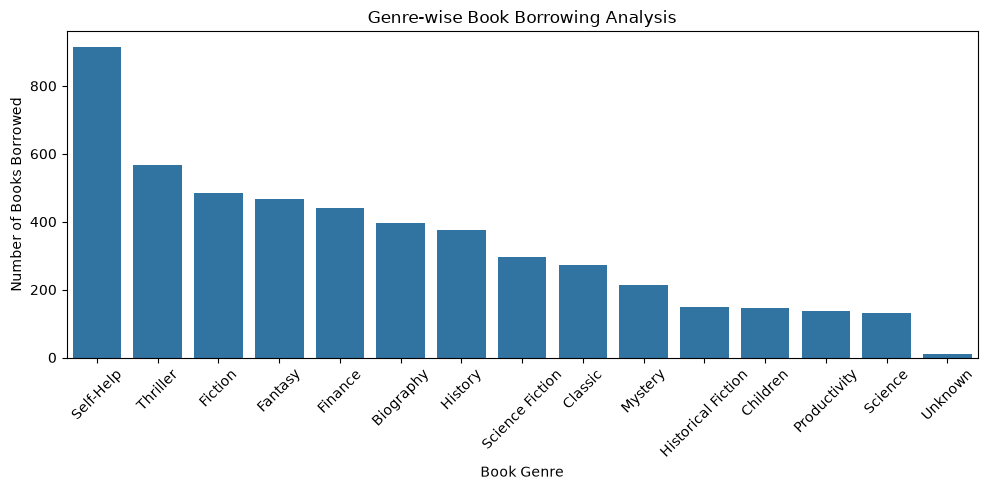

In [101]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Genre',
              order=df['Genre'].value_counts().index)

plt.title('Genre-wise Book Borrowing Analysis')
plt.xlabel('Book Genre')
plt.ylabel('Number of Books Borrowed')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Top 10 Most Borrowed Books

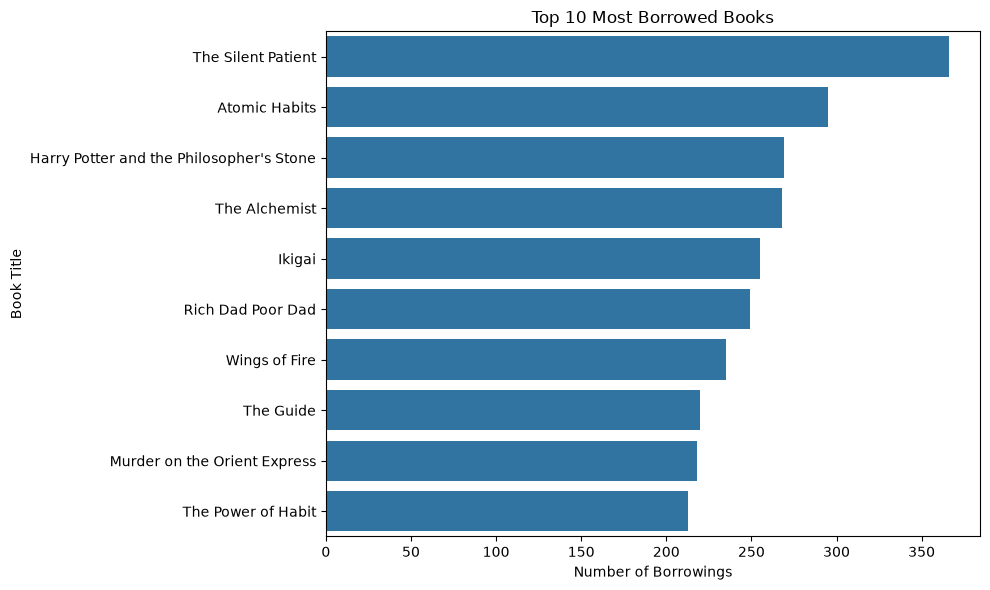

In [102]:
top_books = df['Book_Title'].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(x=top_books.values, y=top_books.index)

plt.title('Top 10 Most Borrowed Books')
plt.xlabel('Number of Borrowings')
plt.ylabel('Book Title')
plt.tight_layout()
plt.show()

## Branch-wise Book Circulation

In [ ]:
branch_data = df['Branch'].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(x=branch_data.index, y=branch_data.values)

plt.title('Branch-wise Book Circulation')
plt.xlabel('Library Branch')
plt.ylabel('Number of Books Borrowed')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

## Monthly Borrowing Trend

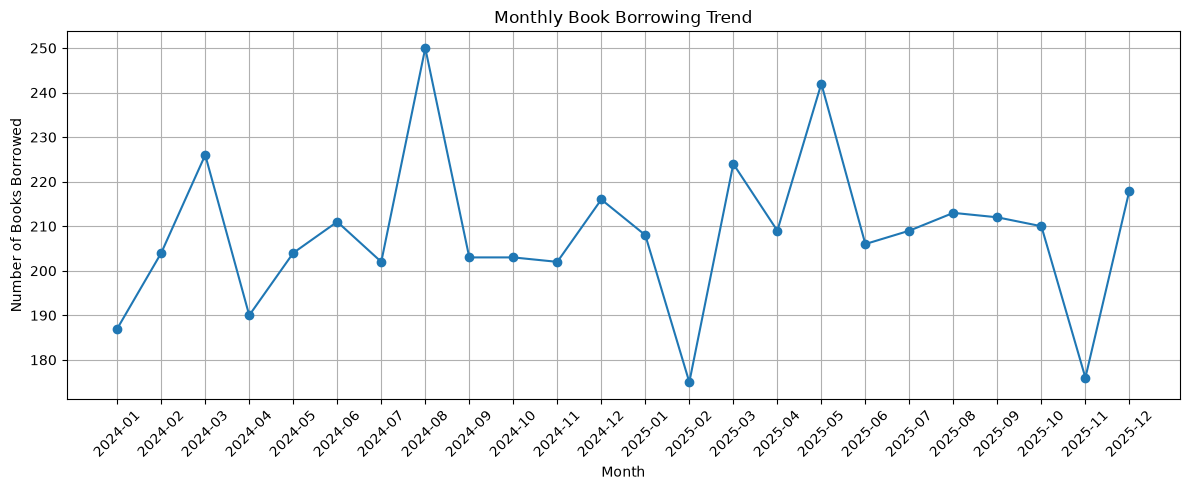

In [104]:
monthly_data = (
    df.groupby(df['Issue_Date'].dt.to_period('M'))
    .size()
)

plt.figure(figsize=(12, 5))

plt.plot(monthly_data.index.astype(str),
         monthly_data.values, marker='o')

plt.title('Monthly Book Borrowing Trend')
plt.xlabel('Month')
plt.ylabel('Number of Books Borrowed')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Membership Type Distribution

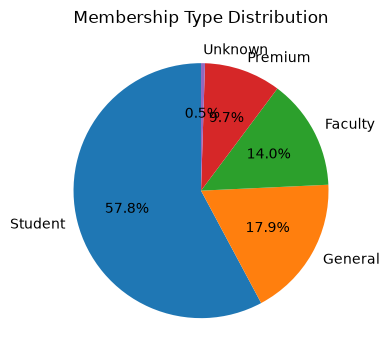

In [ ]:
membership_data = df['Membership_Type'].value_counts()

plt.figure(figsize=(4, 4))

plt.pie(
    membership_data.values,
    labels=membership_data.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Membership Type Distribution')
plt.tight_layout()
plt.show()

## Book Return Status Analysis

In [107]:
return_data = pd.Series(return_status).value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    return_data.values,
    labels=return_data.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Book Return Status Analysis')
plt.tight_layout()
plt.show()

NameError: name 'return_status' is not defined

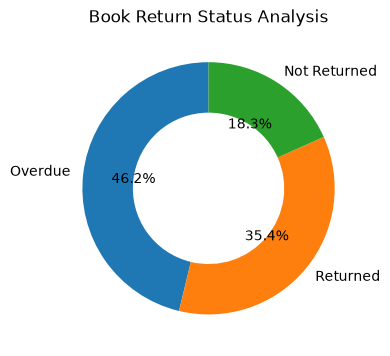

In [121]:
return_data = pd.Series(return_status).value_counts()

plt.figure(figsize=(4, 4))

plt.pie(
    return_data.values,
    labels=return_data.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Book Return Status Analysis')
plt.tight_layout()
plt.show()

In [118]:
return_data = pd.Series(return_status).value_counts()

In [115]:
return_status = np.select(
    [df['Return_Date'].isna(), df['Return_Date'] > df['Due_Date']],
    ['Not Returned', 'Overdue'],
    default='Returned'
)

## **Part 5 – Business Insights**

In [125]:
genre = df['Genre'].value_counts()
print(genre.idxmax())
print(genre.max())

Self-Help
915


In [126]:
branch = df['Branch'].value_counts()
print(branch.idxmax())
print(branch.max())

Central Library
1623


In [128]:
books = df['Book_Title'].value_counts()
print(books.idxmax())
print(books.max())

The Silent Patient
366


In [129]:
membership = df['Membership_Type'].value_counts()
print(membership.idxmax())
print(membership.max())

Student
2891


In [130]:
overdue_count = (
    (df['Return_Date'].notna()) &
    (df['Return_Date'] > df['Due_Date'])
).sum()

In [131]:
print(overdue_count)

2312


In [132]:
print(round(df['Fine_Amount'].sum(), 2))


69660.0


In [133]:
monthly = df.groupby(df['Issue_Date'].dt.to_period('M')).size()
print(monthly.idxmax())
print(monthly.max())

2024-08
250


### **1.Popular Genre**: Self-Help is the most popular genre in the library, with 915 borrowings.

### **2.Branch Performance**: Central Library has the highest circulation, with 1,623 borrowings.

### **3.Membership Activity**: Student members account for the highest number of transactions, with 2,891 borrowings

### **4.Popular Book**: The Silent Patient is the most borrowed book, with 366 borrowings

### **5.Popular Book**: The Silent Patient is the most borrowed book, with 366 borrowings.

### **6.Fine Collection**: The library collected a total of ₹69,660 in fines.

### **7.Monthly Borrowing Trend**: August 2024 recorded the highest borrowing activity, with 250 transactions. This suggests that library usage was highest during this month.

## **Part 6 - Recommendations**

### 1.Reduce Late Returns: Send reminders to members before the book due date.

### 2.Add More Popular Books: Maintain extra copies of frequently borrowed books.

### 3.Promote Other Genres: Encourage readers to explore different book genres.

### 4.Improve Library Services: Improve facilities and services in branches with lower borrowing activity.

### 5.Encourage Student Reading: Organize reading programs and book clubs for students.

### 6.Monitor Overdue Books: Regularly check overdue books and follow up with members.

### 7.Improve Book Availability: Maintain proper stock of books based on member demand.

### 8.Encourage Digital Services: Introduce online book reservations and renewals to make library services easier.